In [1]:
import os
import numpy as np
import pandas as pd
import scanpy as sc
import seaborn as sns
import gseapy as gp
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.colorbar as colorbar

from typing import Tuple, Literal
from anndata import AnnData
from itertools import product

from scipy.stats import pearsonr
import textwrap

#### dataset publication: https://www.nature.com/articles/s41467-019-14118-w

In [2]:
for mod in [np, pd, sc, gp]:
    print(mod, mod.__version__)

<module 'numpy' from '/Users/soeren.becker/micromamba/envs/env_gsea/lib/python3.10/site-packages/numpy/__init__.py'> 2.1.0
<module 'pandas' from '/Users/soeren.becker/micromamba/envs/env_gsea/lib/python3.10/site-packages/pandas/__init__.py'> 2.2.3
<module 'scanpy' from '/Users/soeren.becker/micromamba/envs/env_gsea/lib/python3.10/site-packages/scanpy/__init__.py'> 1.11.1
<module 'gseapy' from '/Users/soeren.becker/micromamba/envs/env_gsea/lib/python3.10/site-packages/gseapy/__init__.py'> 1.1.8


In [3]:
def get_genesets(
    adata: AnnData,
    df_hcd_all: pd.DataFrame,
    celltype_signature: str,
    direction: str,
    threshold_pval: float,
    threshold_lfc: float,
    min_size: int = None,
    max_size: int = None,
) -> Tuple[dict[str, list[str]], pd.DataFrame]:

    # construct signature gene set
    select = ((df_hcd_all.adj_p_value <= threshold_pval) & (df_hcd_all.celltype == celltype_signature))
    if direction == "upregulated":
        select = select & (df_hcd_all.log_fc >= threshold_lfc)
    elif direction == "downregulated":
        select = select & (df_hcd_all.log_fc <= threshold_lfc)
    elif direction == "both":
        select = select & (df_hcd_all.log_fc.abs() >= threshold_lfc)         
    
    df_hcd_ct = df_hcd_all.loc[select]
    gene_set_dict = {}
    gene_set_df = pd.DataFrame()
    for cytokine_i, cytokine in enumerate(df_hcd_ct.cytokine.unique()):
        gene_set = df_hcd_ct.loc[df_hcd_ct.cytokine == cytokine].gene.values
        gene_set_shared = np.intersect1d(gene_set, adata.var_names)
        gene_set_df.loc[cytokine_i, "cytokine"] = cytokine
        gene_set_df.loc[cytokine_i, "num_genes_signature"] = len(gene_set)
        gene_set_df.loc[cytokine_i, "num_shared_genes_signature"] = len(gene_set_shared)
        gene_set_df.loc[cytokine_i, "frac_shared_genes_signature"] = len(gene_set_shared) / len(gene_set)

        if (len(gene_set_shared) < min_size) or (len(gene_set_shared) > max_size): 
            continue
        
        gene_set_dict[cytokine] = gene_set_shared

    return gene_set_dict, gene_set_df


def compute_s2n(adata: AnnData, contrast_column: str, condition_1: str, condition_2: str) -> (pd.DataFrame, pd.DataFrame):
    """
    Compute the signal-to-noise ratio (S2N) for each gene between two conditions in an AnnData object.

    Parameters:
    - adata: AnnData object with gene expression data.
    - contrast_column: Key in `adata.obs` indicating the condition labels (e.g. "disease_state").
    - condition_1: Name of the first condition (e.g., "flare").
    - condition_2: Name of the second condition (e.g., "healthy").
    
    Returns:
    - s2n_scores: pandas Series of S2N values indexed by gene names.
    """
    # Select cells for each condition
    group1 = adata[adata.obs[contrast_column] == condition_1]
    group2 = adata[adata.obs[contrast_column] == condition_2]

    # number of cells per condition
    num_cells_1 = group1.shape[0]
    num_cells_2 = group2.shape[0]
    
    # Get expression matrices
    X1 = group1.X.toarray() if hasattr(group1.X, "toarray") else group1.X
    X2 = group2.X.toarray() if hasattr(group2.X, "toarray") else group2.X

    # Compute mean and std per gene
    mu1 = np.mean(X1, axis=0)
    mu2 = np.mean(X2, axis=0)
    sigma1 = np.std(X1, axis=0, ddof=1)
    sigma2 = np.std(X2, axis=0, ddof=1)

    # Compute S2N
    s2n = (mu1 - mu2) / (sigma1 + sigma2 + 1e-8)  # epsilon to avoid division by zero

    num_cells = pd.DataFrame(index=[f"{condition_1}_vs_{condition_2}"], columns=["num_cells_1", "num_cells_2"], data=[[num_cells_1, num_cells_2]])
    stats = pd.DataFrame(s2n, index=adata.var_names, columns=[f"{condition_1}_vs_{condition_2}"])
    
    return stats, num_cells

  
def compute_ranking_statistic(adata: AnnData, contrast_column: str, contrasts: list[Tuple[str, str]]) -> (pd.DataFrame, pd.DataFrame):
    rnk_stats, num_cells = [], []
    for condition in contrasts:
        _rnk_stats, _num_cells = compute_s2n(
            adata,
            contrast_column=contrast_column,
            condition_1=condition[0],
            condition_2=condition[1]
        )
        rnk_stats.append(_rnk_stats)
        num_cells.append(_num_cells)
    return pd.concat(rnk_stats, axis=1), pd.concat(num_cells, axis=0)

    
def run_enrichment_test(
    adata: AnnData,
    df_hcd_all: pd.DataFrame,
    celltype: Tuple[str, str] = ("B cell", "B"),
    direction: str = "upregulated",
    threshold_pval: float = 0.01,
    threshold_lfc: float = 1.,
    threshold_expression: float = 0,
    contrast_column: str = "disease_state",
    celltype_column: str = "disease_state",
    contrasts: Tuple[str, str] | list[Tuple[str, str]] = None,
    min_size: int = 10,
    max_size: int = 1000,
    permutation_num: int = 1000,
    weight: float = 1.,
    max_obs_per_condition: int | None = None, # None = all
    seed: int = 2025,
    verbose: bool = True,
    threads: int = 6,
) -> pd.DataFrame:

    if not isinstance(contrasts, list):
        assert isinstance(contrasts, Tuple)
        contrasts = [contrasts]
        
    celltype_adata = celltype[0]
    celltype_signature = celltype[1]

    # filter for cell type
    adata = adata[adata.obs[celltype_column] == celltype_adata]
    
    # filter based on gene expression
    adata = adata[:, adata.X.mean(axis=0) >= threshold_expression]

    # get genesets
    gene_set_dict, gene_set_df = get_genesets(
        adata=adata,
        df_hcd_all=df_hcd_all,
        celltype_signature=celltype_signature,
        direction=direction,
        threshold_pval=threshold_pval,
        threshold_lfc=threshold_lfc,
        min_size=min_size,
        max_size=max_size,
    )

    # return adata, gene_set_dict

    if len(gene_set_dict) == 0:
        print("No gene sets passed filtering criteria.")
        return None
    
    # compute ranking stat
    rnk_stats, num_cells_per_condition = compute_ranking_statistic(adata, contrast_column=contrast_column, contrasts=contrasts)
    results = []
    for contrast_name in rnk_stats.columns:
        
        # format stat so that it can be processed be gseapy
        
        rnk = rnk_stats.loc[:, contrast_name]\
            .replace([np.inf, -np.inf], np.nan)\
            .dropna()\
            .sort_values(ascending=False)\
            .to_frame()\
            .rename({contrast_name: 1}, axis=1)\
            .rename_axis("0")
        
        # run enrichment
        gp_res = gp.prerank(
            rnk=rnk,
            gene_sets=gene_set_dict,
            min_size=min_size,
            max_size=max_size,
            permutation_num=permutation_num,
            weight=weight,
            outdir=None,
            seed=seed,
            verbose=verbose,
            threads=threads,
        )
        _res = gp_res.res2d
        _res.loc[:, "contrast"] = contrast_name
        _res.loc[:, "num_cells_1"] = num_cells_per_condition.loc[contrast_name, "num_cells_1"]
        _res.loc[:, "num_cells_2"] = num_cells_per_condition.loc[contrast_name, "num_cells_2"]
        _res.loc[:, "percent_duplicate_ranking_stats"] = (rnk.duplicated(keep="first").sum() / rnk.shape[0]) * 100
        
        results.append(_res)

    # combine results and save hyperparams
    results = pd.concat(results, axis=0, ignore_index=True)
    results.loc[:, "celltype_adata"] = celltype_adata
    results.loc[:, "celltype_signature"] = celltype_signature
    results.loc[:, "celltype_combo"] = f"{celltype_adata} ({celltype_signature})"
    results.loc[:, "direction"] = direction
    results.loc[:, "threshold_pval"] = threshold_pval
    results.loc[:, "threshold_lfc"] = threshold_lfc
    results.loc[:, "threshold_expression"] = threshold_expression
    results.loc[:, "min_size"] = min_size
    results.loc[:, "max_size"] = max_size
    results.loc[:, "permutation_num"] = permutation_num
    results.loc[:, "weight"] = weight
    results.loc[:, "seed"] = seed
    results.loc[:, "threads"] = threads

    results.rename({"Term": "cytokine"}, inplace=True, axis=1)
    results = pd.merge(results, gene_set_df, on="cytokine")
    
    return results

In [ ]:
fig_path = "/Users/soeren.becker/repos/HumanCytokineDict/notebooks/08_usecase_MS/figures_manuscript_programs"
os.makedirs(fig_path, exist_ok=True)

In [ ]:
# pd.read_csv("/Users/soeren.becker/repos/HumanCytokineDict/notebooks/larsen/enrichment_MS/polarization_of_programs_interpretability_new.csv", sep=';', decimal=',')#, index_col=0)

### Load and prepare program signatures

In [ ]:
df_drvi = pd.read_csv("/Users/soeren.becker/repos/HumanCytokineDict/notebooks/04_gene_programs/Amir/significant_effects_df.csv", index_col=0)
interpretability_scores = pd.read_csv("/Users/soeren.becker/repos/HumanCytokineDict/data/drvi/interpretability_scores/combined_score_traverse_effect_pos.csv", index_col=0)
de_anndata = sc.read_h5ad("/Users/soeren.becker/repos/HumanCytokineDict/notebooks/04_gene_programs/Amir/de_anndata_combined_v1.h5ad")
all_effects_df = pd.read_csv("/Users/soeren.becker/repos/HumanCytokineDict/notebooks/04_gene_programs/Amir/all_effects.csv", index_col=0)
significant_effects_df = all_effects_df[all_effects_df['is_significant'] == 1]
significant_effects = significant_effects_df.title.unique()
sig_anndata = de_anndata[:, de_anndata.var.title.isin(significant_effects)]
sig_scores = interpretability_scores.loc[:, sig_anndata.var.original_dim_id.values.astype(str)]

dim2title = dict(de_anndata.var.loc[:, ["original_dim_id", "title"]].astype(str).values)
title2process = dict(all_effects_df.loc[:, ["title", "process_id"]].values)

_df = sig_scores.rename(dim2title, axis=1).rename(title2process, axis=1)

df_prepared = pd.melt(
    _df.reset_index(), 
    id_vars='index', 
    var_name='Category', 
    value_name='Value',
).rename({"index": "gene", "Category": "process_id", "Value": "log_fc"}, axis=1)

df_prepared = df_prepared.loc[df_prepared.log_fc>0]
df_prepared2 = df_drvi.loc[:, ["process_id", "cell_type"]].drop_duplicates()
df_drvi_prepared = df_prepared.merge(df_prepared2, on='process_id', how='left')
df_drvi_prepared.loc[:, "adj_p_value"] = 1e-20 # arbitrary, just need a column with this name
df_drvi_prepared = df_drvi_prepared.rename({"process_id": "cytokine", "cell_type": "celltype"}, axis=1)
df_drvi_prepared

### Load dataset

In [ ]:
adata = sc.read_h5ad("/Users/soeren.becker/repos/HumanCytokineDict/data/use_case_datasets/08_Multiple_Sclerose/Schafflick20_MS_CSF.h5ad")
invalid_labels = [
    "Mono Doublet",
    "contamination1",
    "B cell doublets",
    "doublet",
]
adata = adata[~adata.obs.labels.isin(invalid_labels)]

In [ ]:
hcd_var_names = df_drvi_prepared.gene.unique()
print(len(hcd_var_names))

usecase_var_names = adata.var_names.values
print(len(usecase_var_names))

print(len(np.intersect1d(usecase_var_names, hcd_var_names)))

In [ ]:
sorted(np.array(list(adata.obs.labels.unique())))

In [ ]:
sorted(df_drvi_prepared.celltype.unique())

In [ ]:
celltype_combos = ( # cell type in RA dataset, celltype of gene set signature
    ### T cells ###
    ('CD4', "CD4 T cell"),
    ('CD8a', "CD8 T cell"),
    ('CD8n', "CD8 T cell"),
    ('Tregs', "Treg"),
    ### Monocytes ###
    ('Mono', "CD14 Mono"),
    ('ncMono', "CD16 Mono"),
    ### B cells ###
    ('B1', "B cell"), 
    ('B2', "B cell"),
    ### Natural killer cells ###
    ('NK1', 'NK CD56hi'),
    ('NK2', 'NK CD56hi'),
    ('NK1', 'NK CD56low'),
    ('NK2', 'NK CD56low'),
    ### dendritic cells ###
    ('mDC1', "cDC"),
    ('mDC2', "cDC"),
)

In [ ]:
# fontsize
fs = 6

### CSF

In [ ]:
threshold_pval = 0.05 # arbitrary, all programs will pass
#threshold_lfc = 1.
#threshold_expression = 0.05

all_results_csf = []

for threshold_lfc in [0.5]:#, 0.9]:#, 1, 1.1, 1.2]:
    # for threshold_expression in [0.00001, 0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08, 0.09, 0.1]:
    for threshold_expression in [0.05, 0.06, 0.07, 0.08, 0.09, 0.1]:

        shared_kwargs_csf= {
            "threshold_pval": threshold_pval,
            "threshold_lfc": threshold_lfc,
            "threshold_expression": threshold_expression,
            "direction": "upregulated",
            "min_size": 8,
            "max_size": 1_000,
            "permutation_num": 20_000,
            "verbose": True,
            "adata": adata[adata.obs.CSF == "True"],
            "df_hcd_all": df_drvi_prepared,
        }
        
        for celltype_combo_k, celltype_combo in enumerate(celltype_combos):
        
            results_csf = run_enrichment_test(
                celltype=celltype_combo,
                contrast_column="MS",
                celltype_column="labels",
                contrasts=[("True", "False")],
                **shared_kwargs_csf,
            )
            if results_csf is not None:
                all_results_csf.append(results_csf)

all_results_csf = pd.concat(all_results_csf, axis=0)
all_results_csf.loc[:, "CSF"] = True
all_results_csf.to_csv("./results/all_results_enrichment_programs_csf.csv")

In [12]:
all_results_csf = pd.read_csv("./results/all_results_enrichment_programs_csf.csv")

### Blood

In [ ]:
threshold_pval = 0.05 # arbitrary, all programs will pass

all_results_blood = []

for threshold_lfc in [0.5]:
    for threshold_expression in [0.00001, 0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08, 0.09, 0.1]:

        shared_kwargs_blood= {
            "threshold_pval": threshold_pval,
            "threshold_lfc": threshold_lfc,
            "threshold_expression": threshold_expression,
            "direction": "upregulated",
            "min_size": 8,
            "max_size": 1_000,
            "permutation_num": 20_000,
            "verbose": True,
            "adata": adata[adata.obs.CSF == "False"],
            "df_hcd_all": df_drvi_prepared,
        }
        
        for celltype_combo_k, celltype_combo in enumerate(celltype_combos):
        
            results_blood = run_enrichment_test(
                celltype=celltype_combo,
                contrast_column="MS",
                celltype_column="labels",
                contrasts=[("True", "False")],
                **shared_kwargs_blood,
            )
            
            all_results_blood.append(results_blood)

all_results_blood = pd.concat(all_results_blood, axis=0)
all_results_blood.loc[:, "CSF"] = False
all_results_blood.to_csv("./results/all_results_enrichment_programs_blood.csv")

In [5]:
all_results_blood = pd.read_csv("./results/all_results_enrichment_programs_blood.csv")

In [9]:
program_colors = {
    'CE': '#8dd3c7',
    'CS': '#ffffb3',
    'ES': '#bebada',
    'FC': '#fb8072',
    'GR': '#80b1d3',
    'II': '#fdb462',
    'IT': '#b3de69',
    'MD': '#fccde5',
    'PD': '#d9d9d9',
    'SN': '#bc80bd',
    'TR': '#ccebc5'
}

def clean_celltype_combo_labels(x):
    if isinstance(x, list):
        return [clean_celltype_combo_labels(xx) for xx in x]
    return x.split(" (")[0]

def find_switch_indices(lst):
    """Return indices where the value changes from the previous one."""
    return [0] + [i for i in range(1, len(lst)) if lst[i] != lst[i - 1]]

In [10]:
from tqdm.auto import tqdm
import warnings

def _check_robustness_fractions(
    df_pivot, 
    threshold_qval=0.1, # adjusted p value
    threshold_valid=0.8, # fraction of results required to even consider this condition. I.e. if the test only ran for one set of thresholds, then it is not very robust.
    threshold_below_alpha=0.75, # fraction of results that need to be significant
):
    n_total = np.prod(df_pivot.shape)
    n_valid = n_total - df_pivot.isna().sum().sum()
    n_below_alpha = (df_pivot < threshold_qval).sum().sum() # number of results below pval threshold, i.e., number of significant results
    frac_valid_results = (n_valid / n_total)
    frac_pval_below_alpha = (n_below_alpha / n_valid) # fraction of significant results relative to valid results
    is_robust = (frac_pval_below_alpha > threshold_below_alpha) & (frac_valid_results > threshold_valid)
    return frac_valid_results, frac_pval_below_alpha, is_robust

def check_robustness(
    all_results,
    THRESHOLD_QVAL = 0.1,
    THRESHOLD_BELOW_ALPHA = 0.9,
):
    
    all_thresholds_expression = all_results.threshold_expression.sort_values(ascending = False).unique()
    all_thresholds_lfc = sorted(all_results.threshold_lfc.unique())
    
    df = pd.DataFrame(index=all_thresholds_expression, columns=all_thresholds_lfc)
    df.index.rename("threshold_expression", inplace=True)
    df.columns.rename("threshold_lfc", inplace=True)
    
    robust_results = []
    
    for contrast in tqdm(all_results.contrast.unique()):
        for celltype_combo in all_results.celltype_combo.unique():
            results_ct = all_results.loc[(all_results.celltype_combo == celltype_combo) & (all_results.contrast == contrast)]
            for cytokine in results_ct.cytokine.unique():
                results_ct_cy = results_ct.loc[results_ct.cytokine == cytokine]
                df_pivot = results_ct_cy.pivot(index="threshold_expression", columns="threshold_lfc", values="FDR q-val")
                row_order = df_pivot.index.sort_values(ascending=False)
                with warnings.catch_warnings():
                    warnings.simplefilter(action='ignore', category=FutureWarning)
                    df_combined = pd.concat([df, df_pivot])
                df_merged = df_combined.combine_first(df_pivot)
                df_merged = df_merged.loc[~df_merged.index.duplicated()]
                df_pivot = df_merged.loc[all_thresholds_expression, all_thresholds_lfc].astype(float)
                frac_valid_results, frac_pval_below_alpha, is_robust = _check_robustness_fractions(df_pivot, threshold_qval=THRESHOLD_QVAL, threshold_below_alpha=THRESHOLD_BELOW_ALPHA)
                
                if is_robust:
                    robust_results.append(
                        (
                            celltype_combo, contrast, cytokine,
                            frac_valid_results, frac_pval_below_alpha, is_robust,
                            results_ct_cy.NES.min(), results_ct_cy.NES.max(),
                            THRESHOLD_QVAL,
                            THRESHOLD_BELOW_ALPHA,
                        )
                    )
        
    robust_results = pd.DataFrame(robust_results).rename(
        {0: "celltype_combo", 1: "contrast", 2: "cytokine", 3: "frac_valid", 4: "frac_significant", 5:"is_robust", 6:"NES_min", 7:"NES_max", 8:"qval_threshold", 9: "threshold_frac_below_alpha"},
        axis=1
    )
    return robust_results

/Users/soeren.becker/micromamba/envs/env_gsea/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [13]:
all_results_blood = all_results_blood.loc[all_results_blood.celltype_combo != "NK1 (NK CD56hi)"]
all_results_blood = all_results_blood.loc[all_results_blood.celltype_combo != "NK2 (NK CD56low)"]

robust_results_blood_01 = check_robustness(all_results_blood, THRESHOLD_QVAL=0.1, THRESHOLD_BELOW_ALPHA=0.9)
robust_results_blood_005 = check_robustness(all_results_blood, THRESHOLD_QVAL=0.05, THRESHOLD_BELOW_ALPHA=0.9)
robust_results_blood_001 = check_robustness(all_results_blood, THRESHOLD_QVAL=0.01, THRESHOLD_BELOW_ALPHA=0.9)
robust_results_blood = pd.concat([robust_results_blood_01, robust_results_blood_005, robust_results_blood_001])
robust_results_blood = robust_results_blood.groupby(["celltype_combo", "contrast", "cytokine"])["qval_threshold"].min().to_frame().reset_index()

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00,  4.44it/s]


In [14]:
all_results_csf = all_results_csf.loc[all_results_csf.celltype_combo != "NK1 (NK CD56hi)"]
all_results_csf = all_results_csf.loc[all_results_csf.celltype_combo != "NK2 (NK CD56low)"]

robust_results_csf_01 = check_robustness(all_results_csf, THRESHOLD_QVAL=0.05, THRESHOLD_BELOW_ALPHA=0.9)
robust_results_csf_005 = check_robustness(all_results_csf, THRESHOLD_QVAL=0.05, THRESHOLD_BELOW_ALPHA=0.9)
robust_results_csf_001 = check_robustness(all_results_csf, THRESHOLD_QVAL=0.01, THRESHOLD_BELOW_ALPHA=0.9)
robust_results_csf = pd.concat([robust_results_csf_01, robust_results_csf_005, robust_results_csf_001])
robust_results_csf = robust_results_csf.groupby(["celltype_combo", "contrast", "cytokine"])["qval_threshold"].min().to_frame().reset_index()

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00,  4.55it/s]


In [15]:
idx1 = robust_results_blood.set_index(["celltype_combo", "cytokine"]).index
idx2 = robust_results_csf.set_index(["celltype_combo", "cytokine"]).index
idx_all = idx1.union(idx2)

In [16]:
results_blood = all_results_blood.groupby(["celltype_combo", "cytokine"])["NES"].mean().reset_index()
results_blood = results_blood.set_index(["celltype_combo", "cytokine"])
results_blood = results_blood.loc[results_blood.index.intersection(idx_all)].reset_index()
results_blood.loc[:, "CSF"] = False

In [17]:
results_csf = all_results_csf.groupby(["celltype_combo", "cytokine"])["NES"].mean().reset_index()
results_csf = results_csf.set_index(["celltype_combo", "cytokine"])
results_csf = results_csf.loc[results_csf.index.intersection(idx_all)].reset_index()
results_csf.loc[:, "CSF"] = True

/var/folders/sh/v5nqfs0d4fg8c9jd550tt09h0000gn/T/ipykernel_46871/4154355712.py:11: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  df_annot.loc[:, :] = ""
/var/folders/sh/v5nqfs0d4fg8c9jd550tt09h0000gn/T/ipykernel_46871/4154355712.py:11: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  df_annot.loc[:, :] = ""
/var/folders/sh/v5nqfs0d4fg8c9jd550tt09h0000gn/T/ipykernel_46871/4154355712.py:73: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


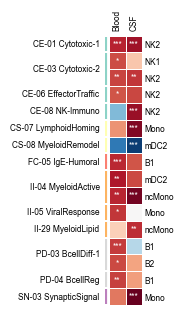

In [28]:
df_both = pd.concat([results_blood, results_csf], axis=0).sort_values(["cytokine", "celltype_combo", "CSF"])
df_both.loc[:, "program_ct"] = df_both.cytokine + "___" + df_both.celltype_combo

df_pivot = df_both.sort_values(["celltype_combo", "cytokine", "CSF"]).pivot(
    index="program_ct", 
    columns="CSF", 
    values="NES",
).astype(float).rename({False: "blood", True: "csf"}, axis=1)

df_annot = df_pivot.copy()
df_annot.loc[:, :] = ""

for row in df_annot.index:
    for col in df_annot.columns:
        program, celltype_combo = row.split("___")
        
        if col == "blood":
            select = ((robust_results_blood.cytokine == program) & (robust_results_blood.celltype_combo == celltype_combo))
            alpha = robust_results_blood.loc[select, "qval_threshold"]
        elif col == "csf":
            select = ((robust_results_csf.cytokine == program) & (robust_results_csf.celltype_combo == celltype_combo))
            alpha = robust_results_csf.loc[select, "qval_threshold"]
        
        if len(alpha) == 0:
            df_annot.loc[row, col] = ""
        else:
            assert len(alpha) == 1
            alpha = alpha.values[0]
            if alpha == 0.1:
                df_annot.loc[row, col] = "*"
            elif alpha == 0.05:
                df_annot.loc[row, col] = "**"
            elif alpha == 0.01:
                df_annot.loc[row, col] = "***"
        

ytick_labels = df_pivot.index.tolist()
left_labels = [label.split('___')[0] for label in ytick_labels]
right_labels = [label.split('___')[1] for label in ytick_labels]

starts = find_switch_indices([l.split(" ")[0] for l in left_labels])
stops =  starts[1:] + [starts[-1]+1]

fig, ax = plt.subplots(figsize=(1.5, 3.5))
heatmap_out = sns.heatmap(
    df_pivot.fillna(0),
    center=0,
    vmin=-df_both.NES.max(),
    vmax=df_both.NES.max(),
    cmap="RdBu_r",
    square=True,
    annot=df_annot,
    annot_kws={"fontsize": 6, "family": "Arial"},
    fmt="",
    ax=ax,
    cbar=False,
    cbar_kws={"shrink": 0.5},
    lw=0.5,
    linecolor="white",
)

plt.ylabel("")
plt.xlabel("")
ax.set_yticks(np.arange(0.5, 0.5+len(left_labels)))
ax.set_yticklabels(left_labels, rotation=0)
ax.tick_params(axis='y', labelright=False, labelleft=True, length=0)

ax.tick_params(axis='both', which='both', length=0)

ax.xaxis.tick_top()
ax.xaxis.set_label_position('top')
plt.xticks([0.5, 1.5], ["Blood", "CSF"], fontsize=6, family="Arial", rotation=90, ha="center")
plt.tight_layout()
fig.canvas.draw()
bbox = ax.get_position()
yrange = bbox.y1 - bbox.y0

for k, (start, stop) in enumerate(zip(starts, stops)):
    color = program_colors[left_labels[start].split("-")[0]]
    ax.vlines(x=-0.2, ymin=start+0.06, ymax=stop-0.06, color=color, lw=3)
    x_text = bbox.x0 - 0.05
    offset_1 = bbox.y1 - start * ((bbox.y1 - bbox.y0) / df_pivot.shape[0])
    offset_2 = bbox.y1 - stop * ((bbox.y1 - bbox.y0) / df_pivot.shape[0])
    center = (offset_1 - offset_2) / 2
    
    if True:
        fig.text(
            y=offset_1 - center,
            x=x_text,
            s=left_labels[start],
            ha='right',
            va="center",
            fontsize=6,
            family="Arial",
            rotation=0
        )

plt.xlim([-0.2, df_pivot.shape[1]])    
ax_pos = ax.get_position()
fig_width = fig.get_figwidth()
ax_right = fig.add_axes([
    # ax_pos.x1 + 0.035,  
    ax_pos.x1 + 0.08,  
    ax_pos.y0,
    0.1,
    ax_pos.height,
])
ax_right.set_xticks([])
ax_right.set_ylim(ax.get_ylim())
ax_right.set_yticks(ax.get_yticks())
ax_right.set_yticklabels(
    clean_celltype_combo_labels(right_labels),
    rotation=0,
    ha="left",
    fontsize=6,
    family="Arial",
)
ax.set_yticklabels([], rotation=0)

ax_right.tick_params(left=False, right=False)
for spine in ax_right.spines.values():
    spine.set_visible(False)

if True:
    plt.savefig(
        os.path.join("./results/enrichment_MS_programs.svg"),
        transparent=True,
        dpi=400,
        bbox_inches="tight",
        pad_inches=0,
    )
plt.show()

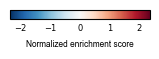

In [32]:
# Get the color map and normalization details from the heatmap
cmap = heatmap_out.get_children()[0].get_cmap()
norm = heatmap_out.get_children()[0].norm

fig_cbar, ax_cbar = plt.subplots(figsize=(1.8, 0.12)) 

cbar = plt.colorbar(
    mappable=plt.cm.ScalarMappable(norm=norm, cmap=cmap),
    cax=ax_cbar,
    label='Normalized enrichment score',
    orientation="horizontal",
)

cbar.ax.tick_params(labelsize=6, length=0)
cbar.ax.set_yticklabels(cbar.ax.get_yticklabels(), fontname='Arial')

# Customize the title
cbar.ax.set_xlabel(
    'Normalized enrichment score',
    fontsize=6,
    fontname='Arial',
    rotation=0,
    labelpad=5
)

if True:
    plt.savefig(
        os.path.join("./results/enrichment_MS_programs_colorbar.svg"),
        transparent=True,
        dpi=400,
        bbox_inches="tight",
        pad_inches=0,
    )

plt.show()